## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Loading model runs
2. Setting technology colors for some visualisations
3. All functions
5. Inspecting results and using of functions for visualisations

### 1) Imports

In [41]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]

### 2) Load networks

In [ ]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "default_tech_high_carbon", "improved_tech_low_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price",
    "default_tech_high_carbon": "Default technology | high CO₂ price",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price",
}
COLORS = {
    "default_tech_low_carbon": "#2878B5",
    "default_tech_high_carbon": "#4C8AAE",
    "improved_tech_low_carbon": "#9E6A45",
    "improved_tech_high_carbon": "#D97732",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))

### 3) Setting technology colors for visualization

In [60]:
tech_colors = {
    # Electricity generation
    "CCGT": "#E68127",                         # Orange
    "CCGT - existing": "#F5B97D",              # Light orange
    "CCGT CCS": "#A84B0F",                     # Burnt orange
    "Biomass plant": "#7CAD45",                # Leaf green
    "Biomass plant CCS": "#276339",            # Dark green
    "Nuclear plant": "#8C58B5",                # Purple
    "Solar": "#E9C52B",                        # Golden yellow
    "Wind onshore": "#37B9AA",                 # Turquoise
    "Wind offshore": "#087F86",                # Deep teal


    # Transport
    "BEV": "#4779D1",                          # Blue
    "BEV - existing": "#A5BEF0",               # Light blue
    "ICE car": "#BC6951",                      # Terracotta
    "ICE car - existing": "#E5AE9D",           # Light terracotta

    # Electricity storage
    "Battery": "#483A88",                      # Indigo

    # Residential demand and heating
    "Residential Appliance": "#737D8C",        # Slate grey
    "Residential gas boiler": "#D8A026",       # Ochre
    "Residential gas boiler - existing": "#EFD18B",
    "Residential heat pump": "#56B5E4",        # Sky blue

    # Large-scale heating
    "Large-scale heat pump": "#008EB8",        # Cyan blue
    "Large-scale heat pump - existing": "#8DD5E7",

    # Industrial boilers
    "Industrial gas boiler": "#A88B55",        # Sand brown
    "Industrial gas boiler - existing": "#D8C7A5",

    # Industrial machinery
    "Industrial machinery - fossil": "#996343",
    "Industrial machinery - fossil - existing": "#CDAF94",
    "Industrial machinery - fossil CCS": "#593B27",
    "Industrial machinery - electricity": "#234D96",

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#B44742",      # Brick red
    "Industrial HTP - fossil - existing": "#DD9692",
    "Industrial HTP - fossil CCS": "#702C36",  # Burgundy

    # Hydrogen production
    "SMR": "#CC743D",                         # Copper
    "SMR - existing": "#E8B79C",
    "SMR with CCS": "#80532B",                # Bronze
    "SMR with CCS - existing": "#BCA07D",
    "Electrolysis": "#7166CF",                # Blue-violet
    "Electrolysis - existing": "#B9B2EB",

    # Emissions
    "CO2 atmosphere": "#333333",              # Charcoal
}

# Alternative names used in your original dictionary.
tech_colors.update({
    "Solar PV": tech_colors["Solar"],
    "Wind turbine - onshore": tech_colors["Wind onshore"],
    "Wind turbine - offshore": tech_colors["Wind offshore"],
})

tech_colors.update({
    # Electricity generation
    "Biomass plant CCS": "#228833",       # Green
    "CCGT": "#F57900",                    # Orange
    "CCGT - existing": "#FFC180",         # Light orange
    "CCGT CCS": "#8C510A",                # Dark brown

    # Emissions
    "CO2 atmosphere": "#333333",          # Charcoal

    # Transport
    "ICE car": "#0077BB",                 # Blue
    "ICE car - existing": "#91C9EB",       # Light blue

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#CC3311",                 # Vermilion
    "Industrial HTP - fossil - existing": "#F3A18D",      # Light salmon
    "Industrial HTP - fossil CCS": "#882255",             # Burgundy

    # Industrial low-temperature heating
    "Industrial gas boiler": "#AA4499",                  # Purple
    "Industrial gas boiler - existing": "#D8ACD0",       # Light purple

    # Industrial machinery
    "Industrial machinery - fossil": "#008878",          # Teal
    "Industrial machinery - fossil - existing": "#8CD3C7",  # Light teal
    "Industrial machinery - fossil CCS": "#004C46",      # Dark teal

    # Residential heating
    "Residential gas boiler": "#D4AA00",                 # Mustard
    "Residential gas boiler - existing": "#F5DF87",       # Light yellow

    # Hydrogen production
    "SMR": "#6655CC",                     # Violet
    "SMR - existing": "#BDB3EA",          # Light violet
    "SMR with CCS": "#596B28",            # Olive
    "SMR with CCS - existing": "#BCC995", # Light olive
})

### 4) Functions

In [70]:
HP_CARRIER = 'Large-scale heat pump'
HEAT_CARRIER = 'Industrial LTP'
CO2_CARRIER = 'CO2 atmosphere'


def _periods(n):
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError('Expected multi-investment-period snapshots.')
    return list(n.investment_periods)


def _snapshots(n, year):
    s = n.snapshots[n.snapshots.get_level_values(0) == year]
    if len(s) == 0:
        raise ValueError(f'No snapshots for {year}.')
    return s


def _weights(n, s):
    w = n.snapshot_weightings.loc[s, 'generators'].astype(float)
    if w.isna().any() or (w <= 0).any():
        raise ValueError('Missing or non-positive snapshot weights.')
    return w


def _active(n, ids, year):
    # Prefer PyPSA's activity logic, including older surviving vintages.
    if hasattr(n, 'get_active_assets'):
        return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
    build = n.links.loc[ids, 'build_year'].fillna(0)
    lifetime = n.links.loc[ids, 'lifetime'].fillna(np.inf)
    return ids[(build.le(year) & (build + lifetime).gt(year)).to_numpy()]


def _links(n, carrier):
    # Include the separately labelled existing technologies in your figures.
    return n.links.index[n.links.carrier.isin([carrier, carrier + ' - existing'])]


def _nominal(n, ids):
    if 'p_nom_opt' not in n.links:
        raise ValueError('Missing p_nom_opt; load solved networks.')
    return n.links.loc[ids, 'p_nom_opt'].astype(float)


def _dense_link(n, attribute, s, ids, default=0.0):
    static = n.links[attribute].reindex(ids) if attribute in n.links else pd.Series(default, index=ids)
    out = pd.DataFrame(
        np.tile(static.to_numpy(dtype=float), (len(s), 1)), index=s, columns=ids
    )
    dynamic = getattr(n.links_t, attribute, None)
    if dynamic is not None and not dynamic.empty:
        shared = ids.intersection(dynamic.columns)
        if len(shared):
            # Dynamic values take precedence; missing values fall back to static.
            out.loc[:, shared] = dynamic.reindex(index=s, columns=shared).combine_first(out[shared])
    return out


def _ports(n):
    return sorted(
        [c for c in n.links.columns if re.fullmatch(r'bus\d+', c)],
        key=lambda c: int(c[3:])
    )


def _port_flow(n, port, s, ids):
    if len(ids) == 0:
        return pd.DataFrame(index=s, columns=ids, dtype=float)
    table = getattr(n.links_t, 'p' + port[3:], None)
    if table is None or table.empty:
        raise ValueError(f'Missing solved Link p{port[3:]} dispatch.')
    missing = ids.difference(table.columns)
    if len(missing):
        raise ValueError(f'Missing {port} dispatch for: {list(missing)}')
    return table.loc[s, ids]


def _style(ax, ylabel):
    ax.set_xlabel('Model year')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.25)


def _legend(fig, ax, title):
    h, l = ax.get_legend_handles_labels()
    if h:
        fig.legend(h, l, loc='lower center', ncol=2, frameon=False, fontsize=9)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0.15, 1, 0.94])


def plot_loaded_hp_parameters(networks, scenarios, labels, colors):
    """Plot actual static parameters by vintage; return a detailed input table.

    capital_cost is reported in its stored model units, NOT assumed €/kW/year.
    Time-dependent efficiency ranges are reported separately in the table.
    """
    rows = []
    for scenario in scenarios:
        n = networks[scenario]
        ids = _links(n, HP_CARRIER)
        for asset in ids:
            row = {'scenario': scenario, 'Link': asset}
            for col in ['carrier', 'build_year', 'lifetime', 'capital_cost',
                        'efficiency', 'marginal_cost', 'p_nom', 'p_nom_opt',
                        'p_nom_min', 'p_nom_max', 'p_nom_extendable', 'bus0', 'bus1']:
                row[col] = n.links.at[asset, col] if col in n.links else np.nan
            s = n.snapshots
            eff = _dense_link(n, 'efficiency', s, pd.Index([asset]))[asset]
            row['COP_min_all_snapshots'] = eff.min()
            row['COP_max_all_snapshots'] = eff.max()
            rows.append(row)
    table = pd.DataFrame(rows)
    if table.empty:
        raise ValueError('No heat-pump Links found.')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, unit in zip(axes, ['capital_cost', 'efficiency'],
                            ['Stored model units', 'Static COP']):
        for scenario in scenarios:
            # Exclude existing assets from the new-vintage parameter curves.
            d = table[(table.scenario == scenario) & (table.carrier == HP_CARRIER)]
            grouped = d.groupby('build_year')[col].agg(['min', 'max']).sort_index()
            if grouped.empty:
                continue
            x = grouped.index.to_numpy(dtype=float)
            ax.plot(x, grouped['min'], marker='o', color=colors[scenario],
                    label=labels[scenario],
                    linestyle='--' if 'high_carbon' in scenario else '-')
            ax.fill_between(x, grouped['min'].to_numpy(dtype=float),
                            grouped['max'].to_numpy(dtype=float),
                            color=colors[scenario], alpha=0.12)
        ax.set_title(col)
        ax.set_xlabel('Build year / vintage')
        ax.set_ylabel(unit)
        ax.grid(alpha=0.25)
    _legend(fig, axes[0], 'Loaded heat-pump parameters (shading = variation within vintage)')
    plt.show()
    return table


def hp_diagnostics(n):
    """Annual energy, dynamic-COP-aware reference capacity, and utilisation.

    Thermal reference capacity = weighted mean of active input capacity × COP.
    Input utilisation uses actual p0 and installed input capacity. This avoids
    incorrectly using a single COP to interpret a variable-COP heat pump.
    """
    ids = _links(n, HP_CARRIER)
    if len(ids) == 0:
        raise ValueError('No heat-pump Links found.')
    if not n.buses.loc[n.links.loc[ids, 'bus1'], 'carrier'].eq(HEAT_CARRIER).all():
        raise ValueError(f'Expected all heat-pump bus1 carriers to be {HEAT_CARRIER!r}.')
    rows = []
    for year in _periods(n):
        s = _snapshots(n, year)
        w = _weights(n, s)
        hours = w.sum()
        active = _active(n, ids, year)
        cap = _nominal(n, active)
        heat = -_port_flow(n, 'bus1', s, ids).sum(axis=1)
        power = _port_flow(n, 'bus0', s, ids).sum(axis=1)
        heat_mwh = heat.mul(w).sum()
        power_mwh = power.mul(w).sum()
        cop = _dense_link(n, 'efficiency', s, active, default=1.0)
        thermal = cop.mul(cap, axis=1).sum(axis=1)
        thermal_mean = thermal.mul(w).sum() / hours
        pmax = _dense_link(n, 'p_max_pu', s, active, default=1.0)
        available_input_mwh = pmax.mul(cap, axis=1).sum(axis=1).mul(w).sum()
        rows.append({
            'year': year,
            'represented_hours': hours,
            'input_capacity_GW': cap.sum() / 1e3,
            'thermal_reference_GW': thermal_mean / 1e3,
            'thermal_min_GW': thermal.min() / 1e3,
            'thermal_max_GW': thermal.max() / 1e3,
            'heat_TWh': heat_mwh / 1e6,
            'electricity_TWh': power_mwh / 1e6,
            'annual_COP': heat_mwh / power_mwh if power_mwh > 1e-6 else np.nan,
            'input_full_load_hours': power_mwh / cap.sum() if cap.sum() > 1e-6 else np.nan,
            'input_utilisation_pct': 100 * power_mwh / (cap.sum() * hours) if cap.sum() > 1e-6 else np.nan,
            'available_input_utilisation_pct': 100 * power_mwh / available_input_mwh if available_input_mwh > 1e-6 else np.nan,
        })
    return pd.DataFrame(rows).set_index('year')


def plot_hp_diagnostics(networks, scenarios, labels, colors):
    tables = {s: hp_diagnostics(networks[s]) for s in scenarios}
    fields = [
        ('thermal_reference_GW', 'Thermal reference capacity', 'GWth'),
        ('input_capacity_GW', 'Installed input capacity', 'GWe'),
        ('annual_COP', 'Annual heat / electricity', 'COP'),
        ('input_full_load_hours', 'Input full-load hours', 'hours'),
        ('input_utilisation_pct', 'Installed input utilisation', '%'),
        ('available_input_utilisation_pct', 'Availability-adjusted input utilisation', '%'),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (field, title, unit) in zip(axes.flat, fields):
        for scenario in scenarios:
            d = tables[scenario]
            ax.plot(d.index, d[field], marker='o', color=colors[scenario],
                    label=labels[scenario],
                    linestyle='--' if 'high_carbon' in scenario else '-')
        ax.set_title(title)
        _style(ax, unit)
        ax.set_xticks(next(iter(tables.values())).index)
        ax.set_ylim(bottom=0)
        if 'utilisation' in field:
            ax.axhline(100, color='grey', linestyle=':', linewidth=1)
    _legend(fig, axes.flat[0], 'Heat-pump capacity and utilisation')
    plt.show()
    return tables


def _heat_series(n, year):
    s = _snapshots(n, year)
    buses = n.buses.index[n.buses.carrier.eq(HEAT_CARRIER)]
    hp = _links(n, HP_CARRIER)
    boiler = _links(n, 'Industrial gas boiler')
    for ids in [hp, boiler]:
        if len(ids) and not n.links.loc[ids, 'bus1'].isin(buses).all():
            raise ValueError('This heat-dispatch plot expects heat output at bus1.')
    hp_heat = -_port_flow(n, 'bus1', s, hp).sum(axis=1)
    boiler_heat = -_port_flow(n, 'bus1', s, boiler).sum(axis=1)
    loads = n.loads.index[n.loads.bus.isin(buses)]
    if len(loads) == 0:
        raise ValueError('No industrial heat Loads found; inspect your demand representation.')
    if n.loads_t.p.empty:
        raise ValueError('Missing solved Load dispatch.')
    demand = n.loads_t.p.loc[s, loads].sum(axis=1)
    power = _port_flow(n, 'bus0', s, hp).sum(axis=1)
    cop = hp_heat.div(power.where(power > 1e-6))
    cap = _nominal(n, _active(n, hp, year))
    available_heat = _dense_link(n, 'efficiency', s, cap.index, 1.0).mul(cap, axis=1)
    available_heat *= _dense_link(n, 'p_max_pu', s, cap.index, 1.0)
    available_heat = available_heat.sum(axis=1)
    return pd.DataFrame({'Demand': demand, 'Heat pump': hp_heat,
                         'Gas boiler': boiler_heat, 'COP': cop,
                         'HP availability envelope': available_heat}, index=s)


def plot_heat_dispatch(networks, scenarios, labels, year=2050, start=None, window_hours=168):
    """Same window across scenarios; default starts at maximum heat demand.

    This shows coarse representative snapshots, not reconstructed hourly data.
    At 35-hour resolution a nominal week contains only about five snapshots.
    """
    ref = networks[scenarios[0]]
    reference = _heat_series(ref, year)
    timestamps = pd.DatetimeIndex(reference.index.get_level_values(1))
    if start is None:
        begin = int(np.argmax(reference['Demand'].to_numpy()))
    else:
        begin = int(timestamps.searchsorted(pd.Timestamp(start)))
        if begin >= len(timestamps):
            raise ValueError('Start is after the final snapshot.')
    if window_hours <= 0:
        raise ValueError('window_hours must be positive.')
    w = _weights(ref, reference.index)
    count = int(np.searchsorted(w.iloc[begin:].cumsum().to_numpy(), window_hours, side='left')) + 1
    selected = reference.index[begin:min(begin + count, len(reference))]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    for ax, scenario in zip(axes.flat, scenarios):
        n = networks[scenario]
        d = _heat_series(n, year)
        if not selected.isin(d.index).all():
            raise ValueError('Scenario snapshots differ; choose a common window.')
        d = d.loc[selected]
        x = pd.DatetimeIndex(d.index.get_level_values(1))
        ax.plot(x, d['Demand'] / 1e3, color='black', label='Heat demand', linewidth=2)
        ax.plot(x, d['Heat pump'] / 1e3, color='#008FAF', marker='o', label='Heat pump')
        ax.plot(x, d['Gas boiler'] / 1e3, color='#AD459B', marker='o', label='Gas boiler')
        ax.plot(x, d['HP availability envelope'] / 1e3, color='#008FAF',
                linestyle=':', label='HP capacity × COP × p_max_pu')
        ax.set_title(labels[scenario])
        ax.set_ylabel('GWth')
        ax.grid(alpha=0.25)
        ax.tick_params(axis='x', rotation=25)
        twin = ax.twinx()
        twin.plot(x, d['COP'], color='grey', linestyle='--', alpha=0.6)
        twin.set_ylabel('Operating COP (grey dashed)')
    _legend(fig, axes.flat[0], f'Industrial heat dispatch: {year}, window starting {timestamps[begin]}')
    plt.show()


def plot_heat_duration(networks, scenarios, labels, year=2050):
    """Each curve is sorted independently: this is NOT a coincident dispatch plot."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    styles = {'Demand': 'black', 'Heat pump': '#008FAF', 'Gas boiler': '#AD459B'}
    for ax, scenario in zip(axes.flat, scenarios):
        n = networks[scenario]
        d = _heat_series(n, year)
        w = _weights(n, d.index)
        for column, color in styles.items():
            order = np.argsort(-d[column].to_numpy(), kind='stable')
            values = d[column].to_numpy()[order] / 1e3
            hours = w.to_numpy()[order]
            edges = np.r_[0, np.cumsum(hours)]
            ax.stairs(values, edges, color=color, label=column)
        ax.set_title(labels[scenario])
        ax.set_xlabel('Weighted hours (independently ranked)')
        ax.set_ylabel('GWth')
        ax.grid(alpha=0.25)
    _legend(fig, axes.flat[0], f'Industrial heat duration curves: {year}')
    plt.show()


def carrier_balance(n, bus_carrier, scale=1e6):
    df = n.statistics.energy_balance(bus_carrier=bus_carrier)
    if not isinstance(df, pd.DataFrame) or df.empty:
        raise ValueError(f'No multi-period energy balance for {bus_carrier!r}.')
    periods = _periods(n)
    if not set(periods).issubset(df.columns):
        raise ValueError(f'Unexpected statistics columns: {list(df.columns)}')
    if isinstance(df.index, pd.MultiIndex):
        level = 'carrier' if 'carrier' in df.index.names else 1
        df = df.groupby(level=level).sum()
    else:
        df = df.groupby(level=0).sum()
    return df[periods].T.fillna(0) / scale


def plot_service_balance(networks, scenarios, labels, bus_carrier, tech_colors=None):
    """Use only a useful-service bus, not an electricity or fuel-input bus.

    Positive = useful service supplied; negative = demand/other withdrawals.
    MWh-equivalent service units are only appropriate if that is your model convention.
    Returns the underlying balance for checking equal service demand.
    """
    tables = {s: carrier_balance(networks[s], bus_carrier) for s in scenarios}
    carriers = sorted(set().union(*(set(d.columns) for d in tables.values())))
    palette = {} if tech_colors is None else tech_colors
    fallback = plt.get_cmap('tab20')
    colors = [palette.get(c, fallback(i % 20)) for i, c in enumerate(carriers)]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    for ax, scenario in zip(axes.flat, scenarios):
        d = tables[scenario].reindex(columns=carriers, fill_value=0)
        d.plot.bar(stacked=True, ax=ax, color=colors, legend=False, rot=0)
        ax.axhline(0, color='black', linewidth=0.7)
        ax.set_title(labels[scenario])
        _style(ax, 'Million model service-units/year')
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='center left', bbox_to_anchor=(0.80, 0.5),
               frameon=False, fontsize=8)
    fig.suptitle(f'Useful-service balance: {bus_carrier}')
    fig.tight_layout(rect=[0, 0, 0.80, 0.94])
    plt.show()
    return tables


def link_co2_flows(n):
    """Direct signed Link injections into atmospheric CO2 buses.

    Excludes atmospheric Stores/Loads used for bookkeeping. Negative values
    are negative Link injections, not proof of permanent carbon removal.
    Capture routed to another bus is not itself atmospheric carbon removal.
    """
    atmospheric_buses = n.buses.index[n.buses.carrier.eq(CO2_CARRIER)]
    if len(atmospheric_buses) == 0:
        raise ValueError(f'No buses with carrier {CO2_CARRIER!r}.')
    rows = {}
    for year in _periods(n):
        s = _snapshots(n, year)
        w = _weights(n, s)
        total = pd.Series(0.0, index=n.links.index)
        for port in _ports(n):
            ids = n.links.index[n.links[port].isin(atmospheric_buses)]
            if len(ids):
                injection = -_port_flow(n, port, s, ids).mul(w, axis=0).sum()
                total.loc[ids] += injection
        grouped = total.groupby(n.links.carrier.fillna('Unlabelled')).sum()
        rows[year] = grouped
    return pd.DataFrame(rows).T.fillna(0) / 1e6


def plot_link_emissions(networks, scenarios, labels, tech_colors=None):
    tables = {s: link_co2_flows(networks[s]) for s in scenarios}
    carriers = sorted(set().union(*(set(d.columns[d.abs().max() > 1e-6]) for d in tables.values())))
    palette = {} if tech_colors is None else tech_colors
    fallback = plt.get_cmap('tab20')
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    for ax, scenario in zip(axes.flat, scenarios):
        d = tables[scenario].reindex(columns=carriers, fill_value=0)
        if carriers:
            d.plot.bar(stacked=True, ax=ax, rot=0, legend=False,
                       color=[palette.get(c, fallback(i % 20)) for i, c in enumerate(carriers)])
        ax.axhline(0, color='black', linewidth=0.7)
        ax.set_title(labels[scenario])
        _style(ax, 'MtCO₂/year')
    h, l = axes.flat[0].get_legend_handles_labels()
    if h:
        fig.legend(h, l, loc='center left', bbox_to_anchor=(0.80, 0.5),
                   frameon=False, fontsize=8)
    fig.suptitle('Direct atmospheric Link emissions — excludes accounting Stores/Loads')
    fig.tight_layout(rect=[0, 0, 0.80, 0.94])
    plt.show()
    return tables


def _bus_residuals(n, s):
    """Per-snapshot KCL for standard PyPSA one-port components and all Link ports.

    Lines/Transformers are included. Custom components and shunt consumption
    are not; check those separately if your model uses them.
    """
    residual = pd.DataFrame(0.0, index=s, columns=n.buses.index)
    def add(frame, buses, sign=1.0):
        if frame.empty:
            return
        grouped = frame.mul(sign).T.groupby(buses.reindex(frame.columns)).sum().T
        shared = residual.columns.intersection(grouped.columns)
        residual.loc[:, shared] += grouped.loc[:, shared]
    for static_name, dynamic_name, sign in [
        ('generators', 'generators_t', 1), ('loads', 'loads_t', -1),
        ('stores', 'stores_t', 1), ('storage_units', 'storage_units_t', 1),
    ]:
        static = getattr(n, static_name)
        if static.empty:
            continue
        dispatch = getattr(getattr(n, dynamic_name), 'p', None)
        if dispatch is None or dispatch.empty:
            raise ValueError(f'Missing solved {static_name} p dispatch.')
        add(dispatch.loc[s], static.bus, sign)
    for port in _ports(n):
        ids = n.links.index[n.links[port].isin(n.buses.index)]
        if len(ids):
            add(_port_flow(n, port, s, ids), n.links.loc[ids, port], -1)
    for static_name, dynamic_name in [('lines', 'lines_t'), ('transformers', 'transformers_t')]:
        static = getattr(n, static_name)
        if static.empty:
            continue
        dynamic = getattr(n, dynamic_name)
        for k in [0, 1]:
            flow = getattr(dynamic, f'p{k}')
            if flow.empty:
                raise ValueError(f'Missing {static_name} p{k}.')
            add(flow.loc[s], static[f'bus{k}'], -1)
    return residual


def audit_networks(networks, scenarios, bus_carriers=('Electricity', HEAT_CARRIER, CO2_CARRIER)):
    """Return hours, gross-absolute and signed residuals, and statistics checks.

    Residual units follow the bus: MW/MWh for energy; tCO2/h and tCO2 for CO2.
    Absolute residual energy cannot cancel across buses or timestamps.
    """
    rows = []
    for scenario in scenarios:
        n = networks[scenario]
        for year in _periods(n):
            s = _snapshots(n, year)
            w = _weights(n, s)
            residual = _bus_residuals(n, s)
            for carrier in bus_carriers:
                buses = n.buses.index[n.buses.carrier.eq(carrier)]
                if len(buses) == 0:
                    continue
                r = residual[buses]
                row = {
                    'scenario': scenario, 'year': year, 'bus_carrier': carrier,
                    'represented_hours': w.sum(),
                    'max_abs_snapshot_residual': r.abs().to_numpy().max(),
                    'annual_abs_residual': r.abs().sum(axis=1).mul(w).sum(),
                    'annual_signed_residual': r.sum(axis=1).mul(w).sum(),
                }
                rows.append(row)
    audit = pd.DataFrame(rows).set_index(['scenario', 'year', 'bus_carrier'])
    # Cross-check manual HP integration against statistics on the heat carrier.
    comparison = []
    for scenario in scenarios:
        n = networks[scenario]
        manual = hp_diagnostics(n)
        stats = carrier_balance(n, HEAT_CARRIER)
        columns = stats.columns.intersection([HP_CARRIER, HP_CARRIER + ' - existing'])
        stat_heat = stats[columns].sum(axis=1)
        for year in manual.index:
            comparison.append({'scenario': scenario, 'year': year,
                               'manual_heat_TWh': manual.at[year, 'heat_TWh'],
                               'statistics_heat_TWh': stat_heat.loc[year],
                               'difference_TWh': stat_heat.loc[year] - manual.at[year, 'heat_TWh']})
    return audit, pd.DataFrame(comparison).set_index(['scenario', 'year'])


def hp_capacity_limits(networks, scenarios):
    """Asset-level input capacity bounds and p_max_pu; not global constraints.

    Equal nominal capacity and p_nom_max is suggestive only when the bound is
    finite and the asset is extendable. A dual is needed to prove it is binding.
    """
    rows = []
    for scenario in scenarios:
        n = networks[scenario]
        ids = _links(n, HP_CARRIER)
        for year in _periods(n):
            s = _snapshots(n, year)
            for asset in _active(n, ids, year):
                cap = n.links.at[asset, 'p_nom_opt']
                upper = n.links.at[asset, 'p_nom_max']
                extendable = bool(n.links.at[asset, 'p_nom_extendable'])
                availability = _dense_link(n, 'p_max_pu', s, pd.Index([asset]), 1.0)[asset]
                rows.append({'scenario': scenario, 'year': year, 'Link': asset,
                             'input_capacity_MW': cap, 'p_nom_max_MW': upper,
                             'extendable': extendable,
                             'near_asset_upper_bound': extendable and np.isfinite(upper) and np.isclose(cap, upper, rtol=1e-5, atol=1e-3),
                             'p_max_pu_min': availability.min(),
                             'p_max_pu_max': availability.max()})
    return pd.DataFrame(rows)

In [61]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(10, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked='True', rot=0, colormap="tab20", ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)

    fig.tight_layout()

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


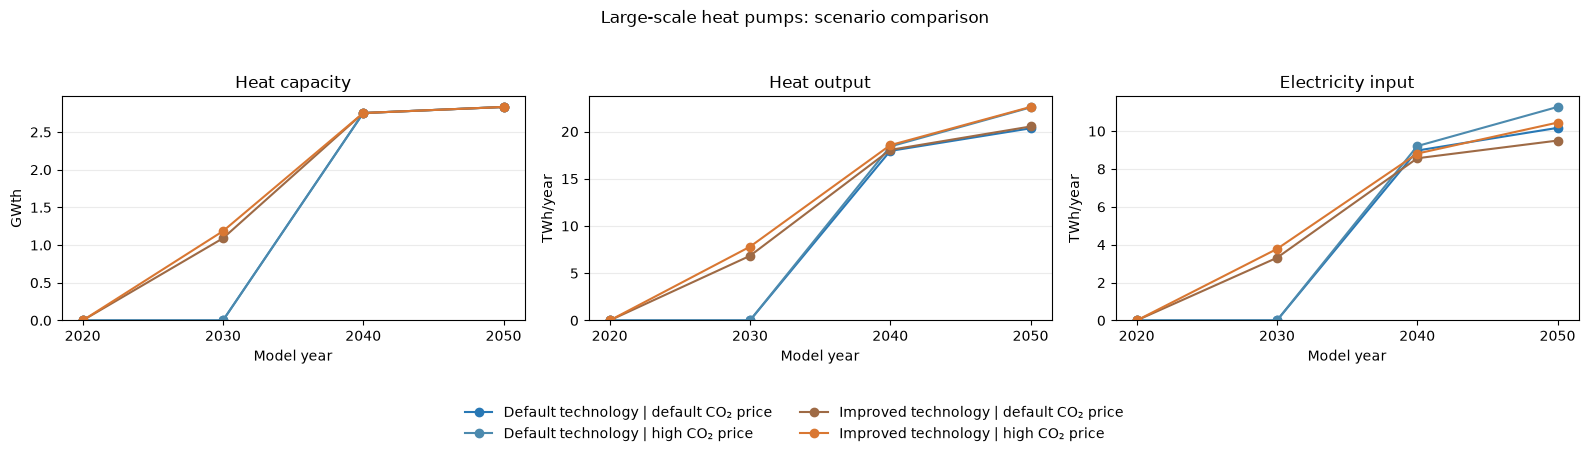

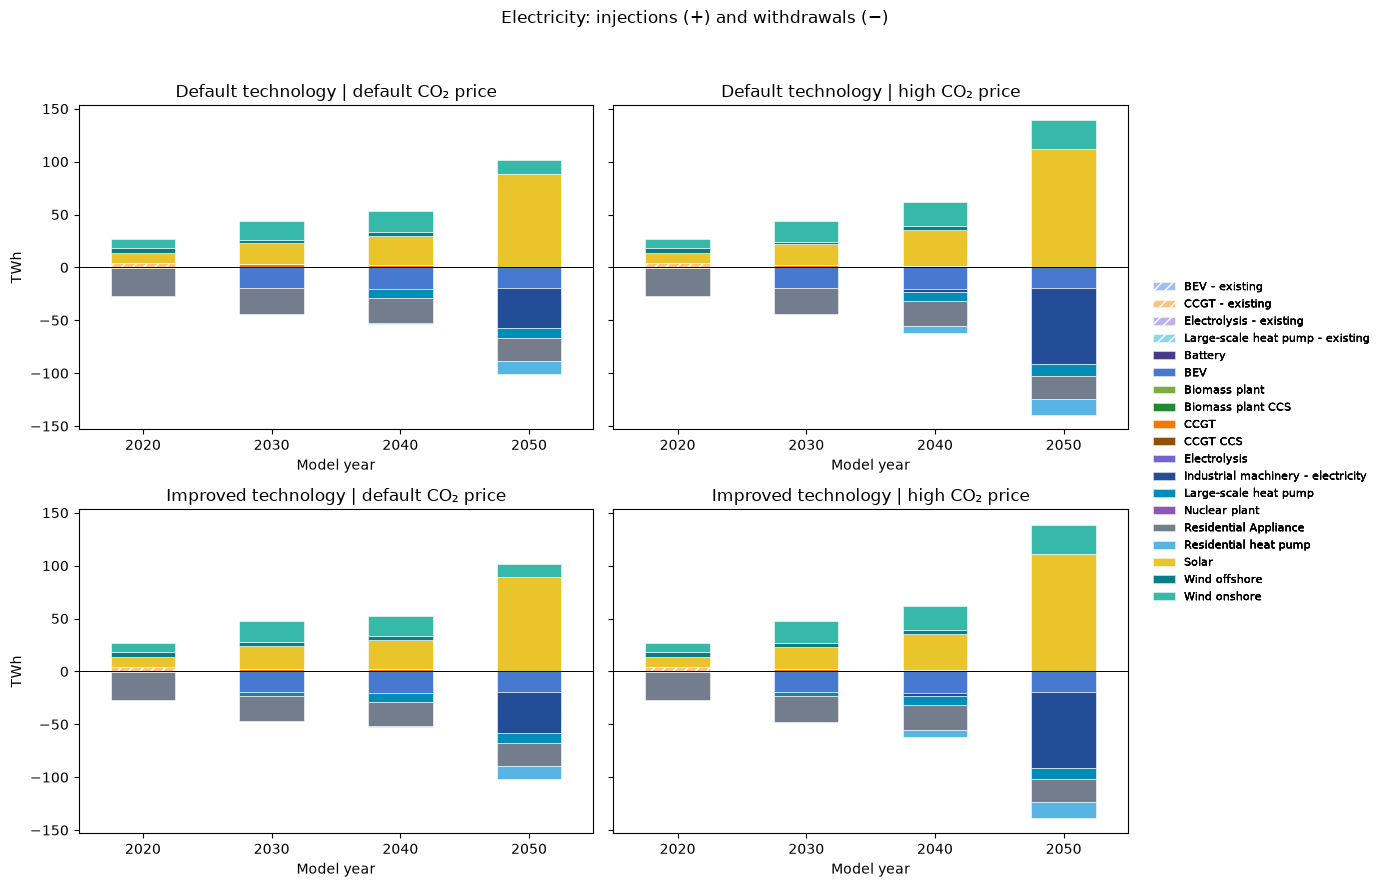

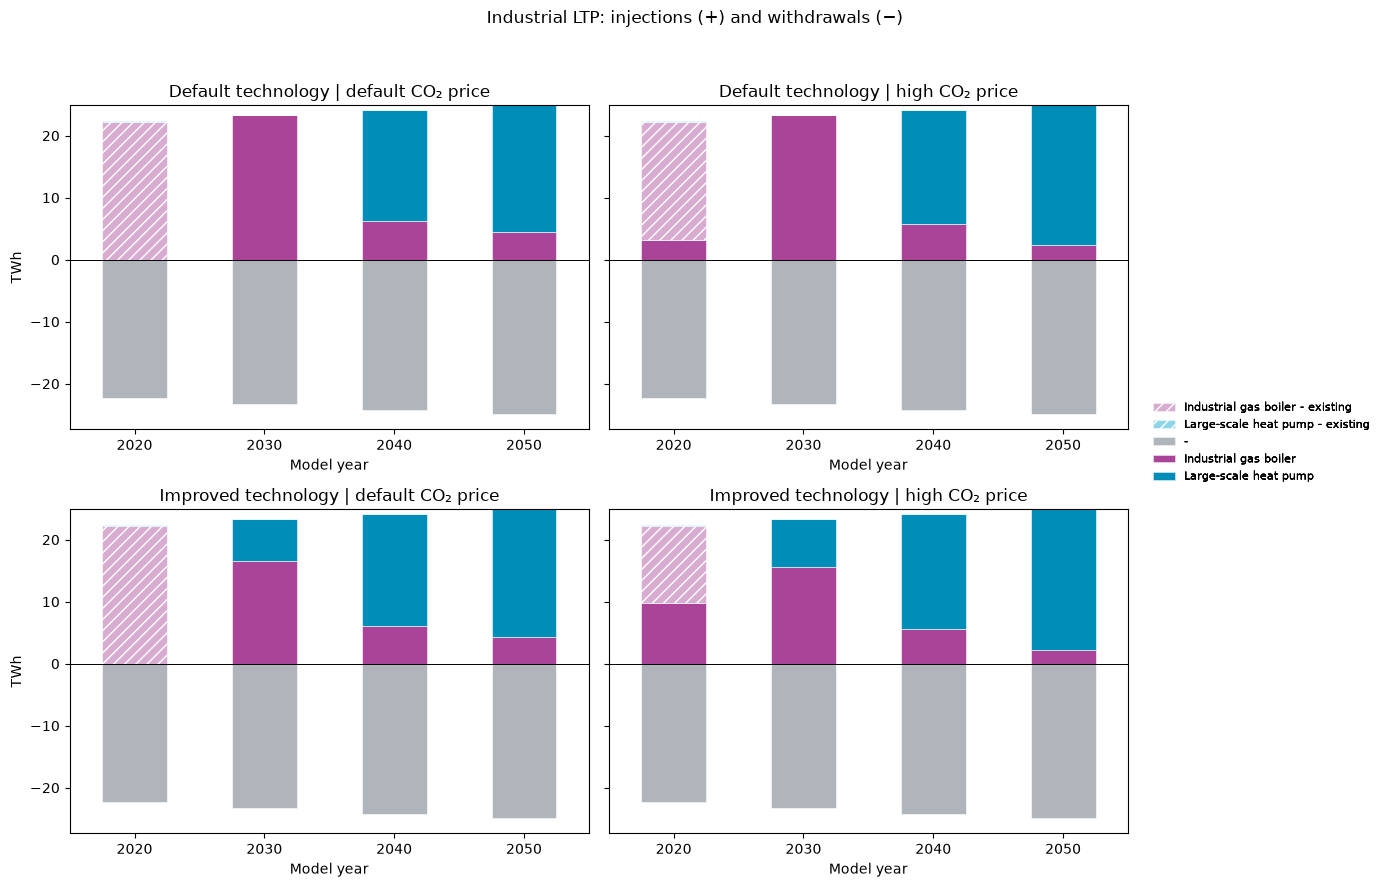

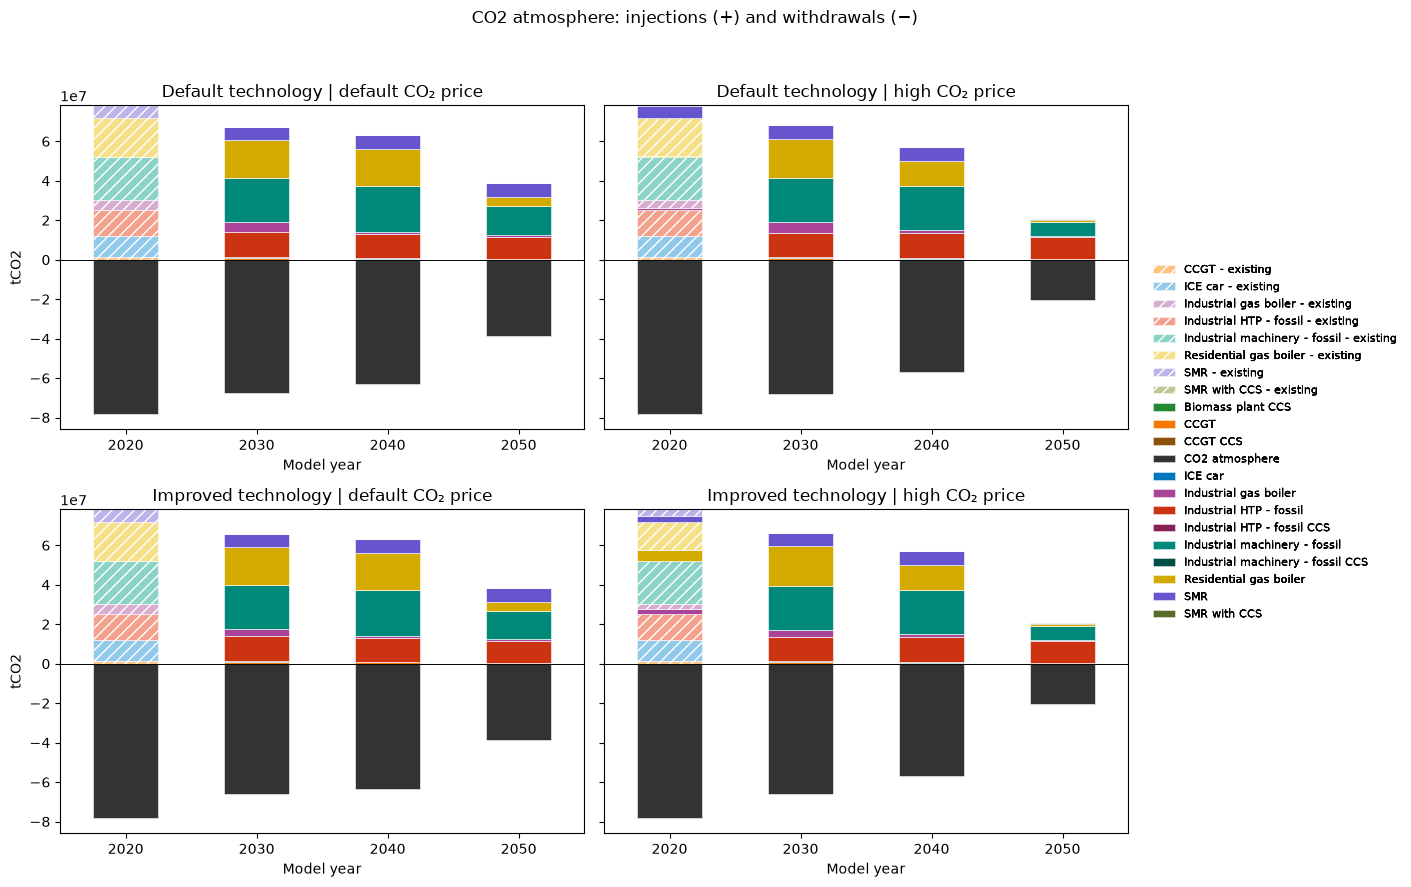

In [ ]:
def heatpump_metrics(n):
    """Active output capacity, annual heat, and annual electricity input.

    Assumes the heat pump is a Link with electricity at bus0 and useful
    heat at bus1, as in the model's two-bus Link implementation.
    Includes active older investment vintages, not just new builds.
    """
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError("Expected multi-period snapshots (period, timestamp).")

    hp = n.links.index[n.links["carrier"].eq("Large-scale heat pump")]
    if len(hp) == 0:
        raise ValueError(f"No large-scale heat-pump Links found in {n.name}.")

    missing = hp.difference(n.links_t.p0.columns).union(
        hp.difference(n.links_t.p1.columns)
    )
    if len(missing):
        raise ValueError(f"Missing optimized heat-pump dispatch: {list(missing)}")

    periods = list(n.investment_periods)
    result = pd.DataFrame(
        index=pd.Index(periods, name="Model year"),
        columns=["Heat capacity (GWth)", "Heat output (TWh/year)",
                 "Electricity input (TWh/year)"],
        dtype=float,
    )

    for year in periods:
        # Link p_nom is input capacity. Multiply by COP/efficiency to obtain
        # heat-output capacity. Do not sum expired or future vintages.
        active_mask = (
            n.links.loc[hp, "build_year"].le(year)
            & (n.links.loc[hp, "build_year"] + n.links.loc[hp, "lifetime"]).gt(year)
        )
        active = hp[active_mask.to_numpy()]
        result.loc[year, "Heat capacity (GWth)"] = (
            n.links.loc[active, "p_nom_opt"]
            * n.links.loc[active, "efficiency"]
        ).sum() / 1e3

        snapshots = n.snapshots[n.snapshots.get_level_values(0) == year]
        # These weights account for the hours represented by each snapshot.
        # Do not multiply by the decade's investment-period weighting here:
        # the result is annual energy, not total energy over the whole decade.
        weights = n.snapshot_weightings.loc[snapshots, "generators"]
        heat = -n.links_t.p1.loc[snapshots, hp].sum(axis=1)
        electricity = n.links_t.p0.loc[snapshots, hp].sum(axis=1)
        result.loc[year, "Heat output (TWh/year)"] = heat.mul(weights).sum() / 1e6
        result.loc[year, "Electricity input (TWh/year)"] = (
            electricity.mul(weights).sum() / 1e6
        )

    return result


metrics = {scenario: heatpump_metrics(n) for scenario, n in networks.items()}

# FIGURE 1: Direct comparison of the heat-pump results.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, next(iter(metrics.values())).columns):
    for scenario in SCENARIOS:
        ax.plot(
            metrics[scenario].index,
            metrics[scenario][metric],
            label=LABELS[scenario],
            color=COLORS[scenario],
            linestyle="--" if scenario.endswith("high") else "-",
            marker="o",
        )
    ax.set_title(metric.split(" (")[0])
    ax.set_ylabel(metric.split("(")[1].rstrip(")"))
    ax.set_xlabel("Model year")
    ax.set_xticks(next(iter(metrics.values())).index)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Large-scale heat pumps: scenario comparison")
fig.tight_layout(rect=[0, 0.16, 1, 0.94])
plt.show()


def plot_energy_balance_comparison(bus_carrier="Electricity", unit="TWh"):
    """Four stacked energy balances, adapted from the supplied functions.

    Positive bars are injections into the selected bus carrier;
    negative bars are withdrawals. Values use PyPSA's statistics aggregation.
    Suitable for energy carriers; use unit='tCO2' for emissions carriers.
    """
    if unit not in {"TWh", "MWh", "tCO2"}:
        raise ValueError("Choose TWh, MWh, or tCO2.")
    scale = 1e6 if unit == "TWh" else 1.0
    balances = {}
    for scenario, n in networks.items():
        df = n.statistics.energy_balance(bus_carrier=bus_carrier)
        if not isinstance(df, pd.DataFrame):
            raise ValueError("Expected statistics columns to represent model years.")
        if not set(n.investment_periods).issubset(df.columns):
            raise ValueError(f"Unexpected statistics columns: {list(df.columns)}")
        if df.empty:
            raise ValueError(f"No energy balance found for {bus_carrier!r}.")
        # Aggregate duplicate carriers rather than simply relabelling rows.
        if isinstance(df.index, pd.MultiIndex):
            level = "carrier" if "carrier" in df.index.names else 1
            df = df.groupby(level=level).sum()
        else:
            df = df.groupby(level=0).sum()
        balances[scenario] = df.loc[:, list(n.investment_periods)].T / scale

    carriers = sorted(set().union(*(set(df.columns) for df in balances.values())))
    # Retrieve carrier colors from your tech_colors dictionary.
    # Use neutral grey for carriers without a defined color.
    colors = {c: tech_colors.get(c, "#B0B5BC") for c in carriers}
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    for ax, scenario in zip(axes.flat, SCENARIOS):
        df = balances[scenario].reindex(columns=carriers, fill_value=0).fillna(0)
        df.plot.bar(
            stacked=True,
            rot=0,
            ax=ax,
            color=[colors[c] for c in carriers],
            edgecolor="white",
            linewidth=0.4,
            legend=False,
        )
        # Each container corresponds to one carrier in the stacked bar chart.
        for carrier, container in zip(carriers, ax.containers):
            if carrier.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(LABELS[scenario])
        ax.set_ylabel(unit)
        ax.set_xlabel("Model year")
        ax.grid(False)
        handles, labels = axes.flat[0].get_legend_handles_labels()

        # Existing technologies first; alphabetical order within each group.
        legend_items = sorted(
            zip(handles, labels),
            key=lambda item: (
                not item[1].endswith(" - existing"),
                item[1].lower(),),)

        sorted_handles, sorted_labels = zip(*legend_items)

        fig.legend( sorted_handles, sorted_labels, loc="center left", bbox_to_anchor=(0.82, 0.5), 
                   frameon=False,
                    fontsize=8,)
        
    fig.suptitle(f"{bus_carrier}: injections (+) and withdrawals (−)")
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()


# FIGURE 2: Electricity balances for all four scenarios.
plot_energy_balance_comparison("Electricity", unit="TWh")

# Optional: uncomment ONE of these to inspect another balance.
# Use exact bus-carrier names from your input database.
# plot_energy_balance_comparison("Residential heat", unit="TWh")
plot_energy_balance_comparison("Industrial LTP", unit="TWh")
# plot_energy_balance_comparison("Hydrogen", unit="TWh")
plot_energy_balance_comparison("CO2 atmosphere", unit="tCO2")

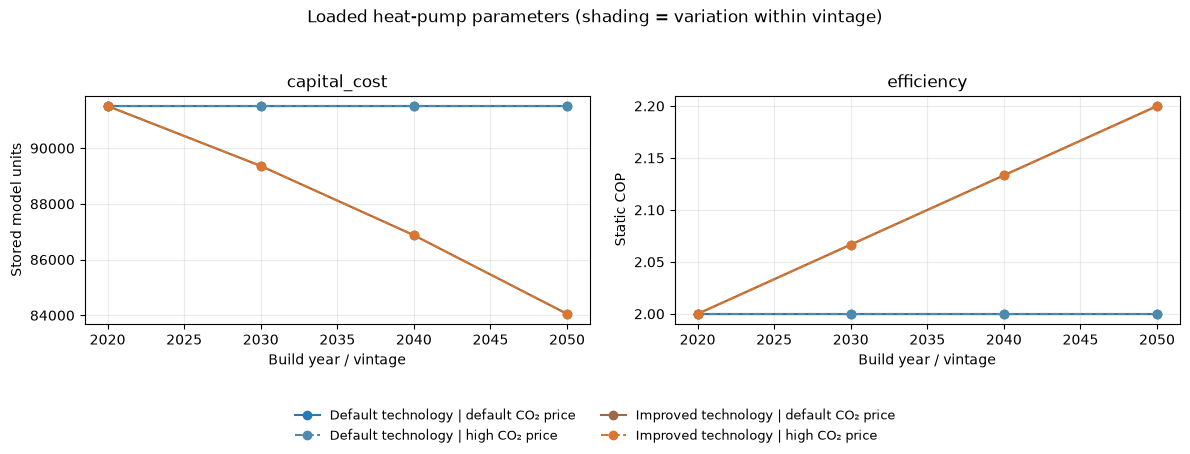


LOADED HEAT-PUMP PARAMETERS
                 scenario                                  Link                          carrier  build_year  lifetime  capital_cost  efficiency  marginal_cost  p_nom   p_nom_opt  p_nom_min  p_nom_max  p_nom_extendable        bus0           bus1  COP_min_all_snapshots  COP_max_all_snapshots
  default_tech_low_carbon            Large-scale heat pump_2020            Large-scale heat pump        2020      20.0  91514.340595    2.000000            0.0    0.0    0.000000        0.0        inf              True Electricity Industrial LTP               2.000000               2.000000
  default_tech_low_carbon Large-scale heat pump - existing_2020 Large-scale heat pump - existing        2020       4.0  16000.000000    2.000000            0.0    0.0   25.000000       25.0       25.0              True Electricity Industrial LTP               2.000000               2.000000
  default_tech_low_carbon            Large-scale heat pump_2030            Large-scale heat pum

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

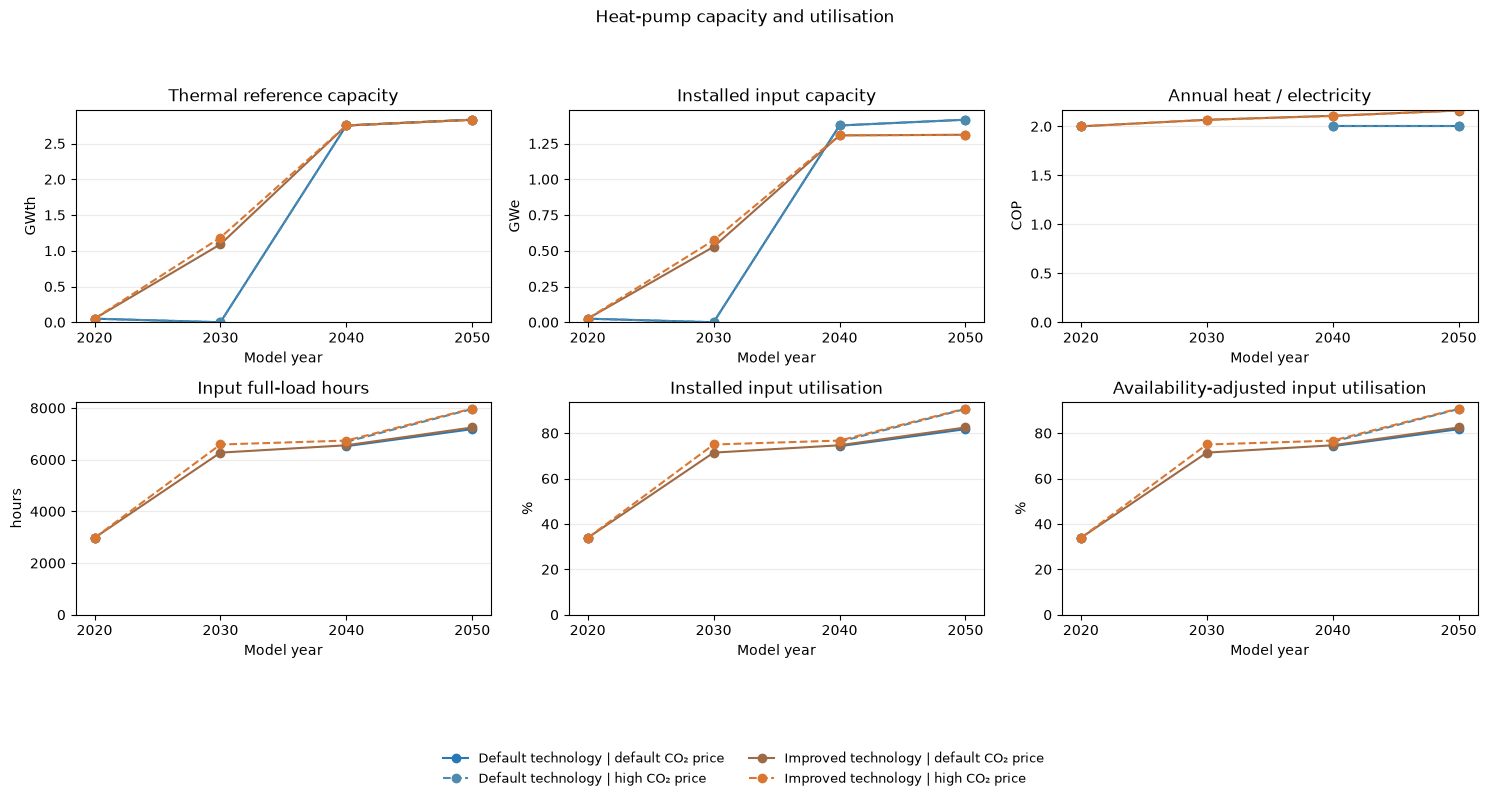


ANNUAL HEAT-PUMP DIAGNOSTICS
                                represented_hours  input_capacity_GW  thermal_reference_GW  thermal_min_GW  thermal_max_GW  heat_TWh  electricity_TWh  annual_COP  input_full_load_hours  input_utilisation_pct  available_input_utilisation_pct
scenario                  year                                                                                                                                                                                                                  
default_tech_low_carbon   2020             8785.0             0.0250                0.0500          0.0500          0.0500    0.1488           0.0744      2.0000              2975.0000                33.8645                          33.8645
                          2030             8785.0             0.0000                0.0000          0.0000          0.0000   -0.0000          -0.0000         NaN                    NaN                    NaN                              NaN
      

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

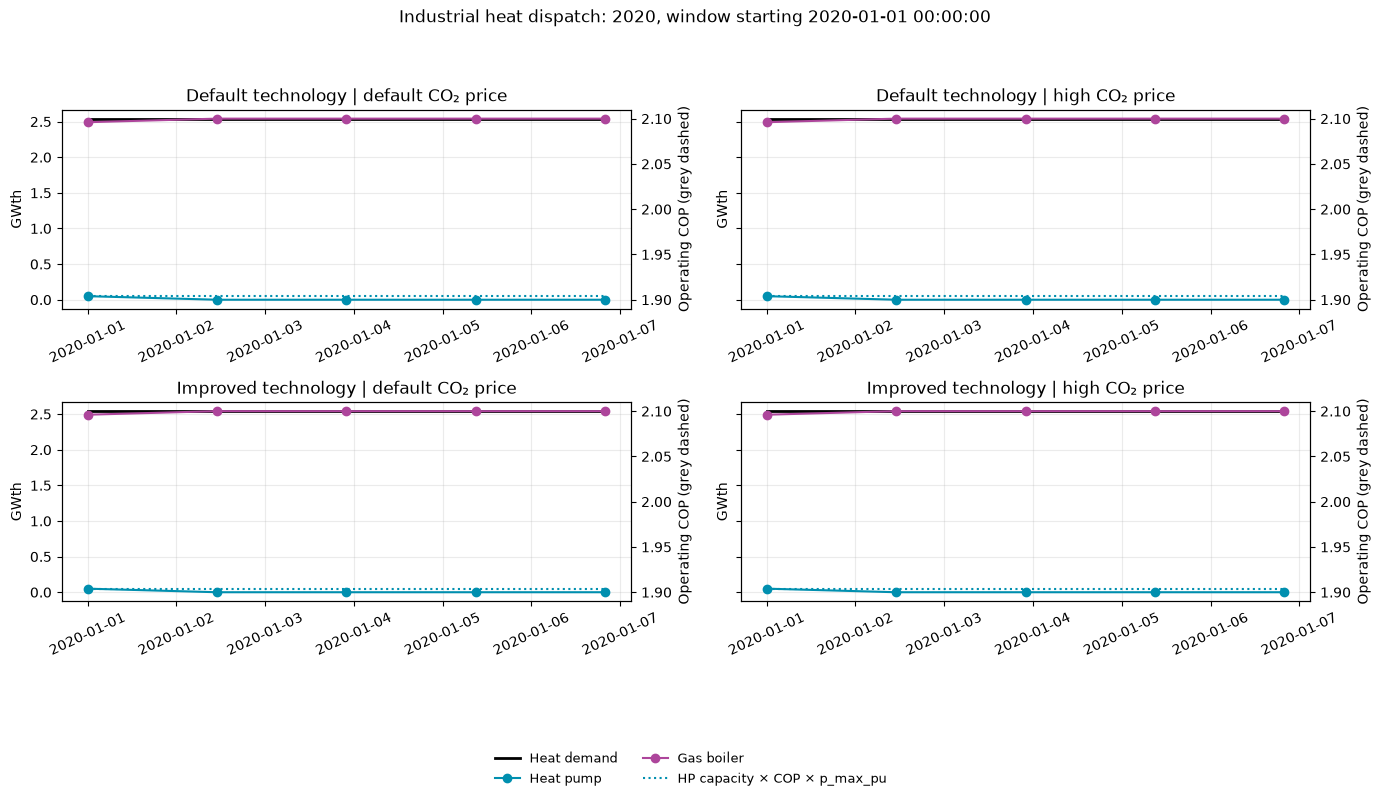

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

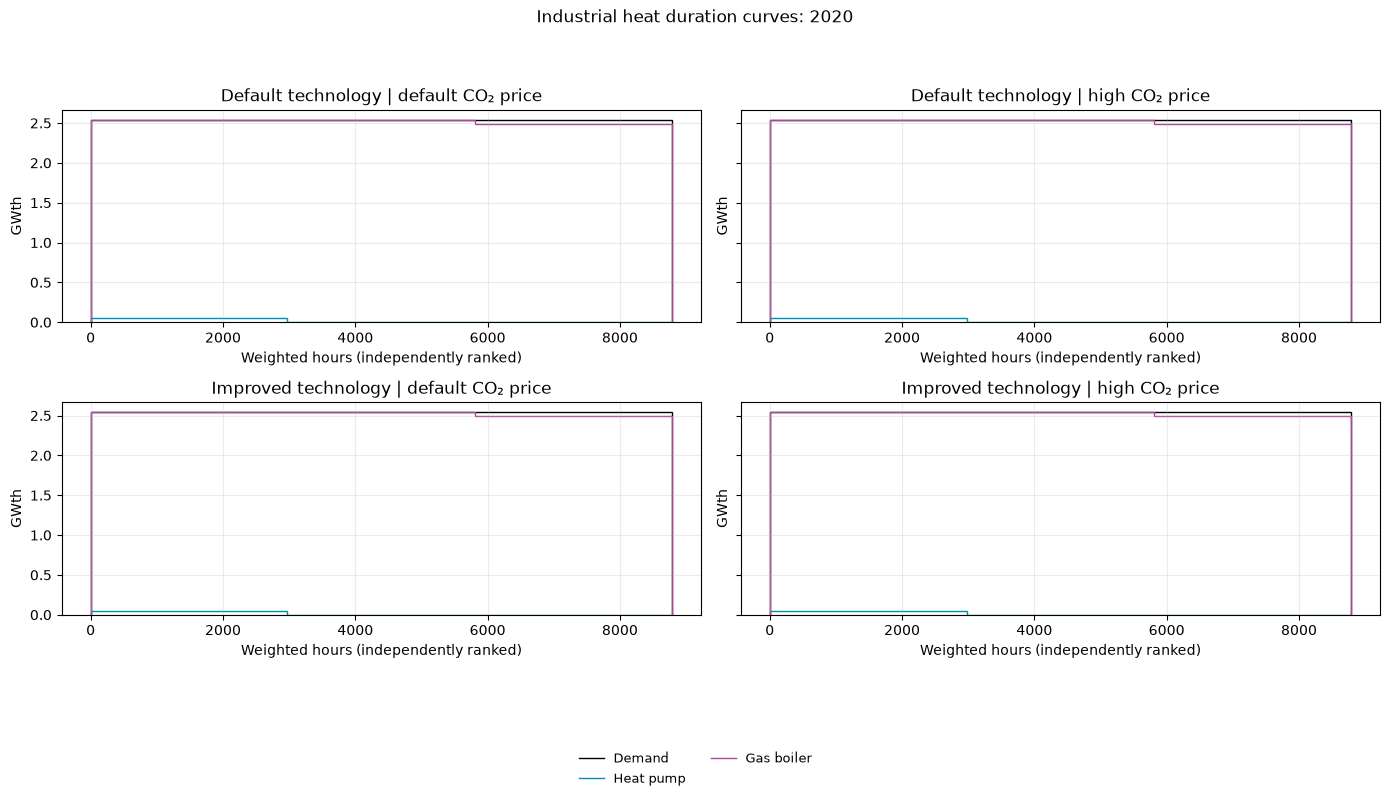

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

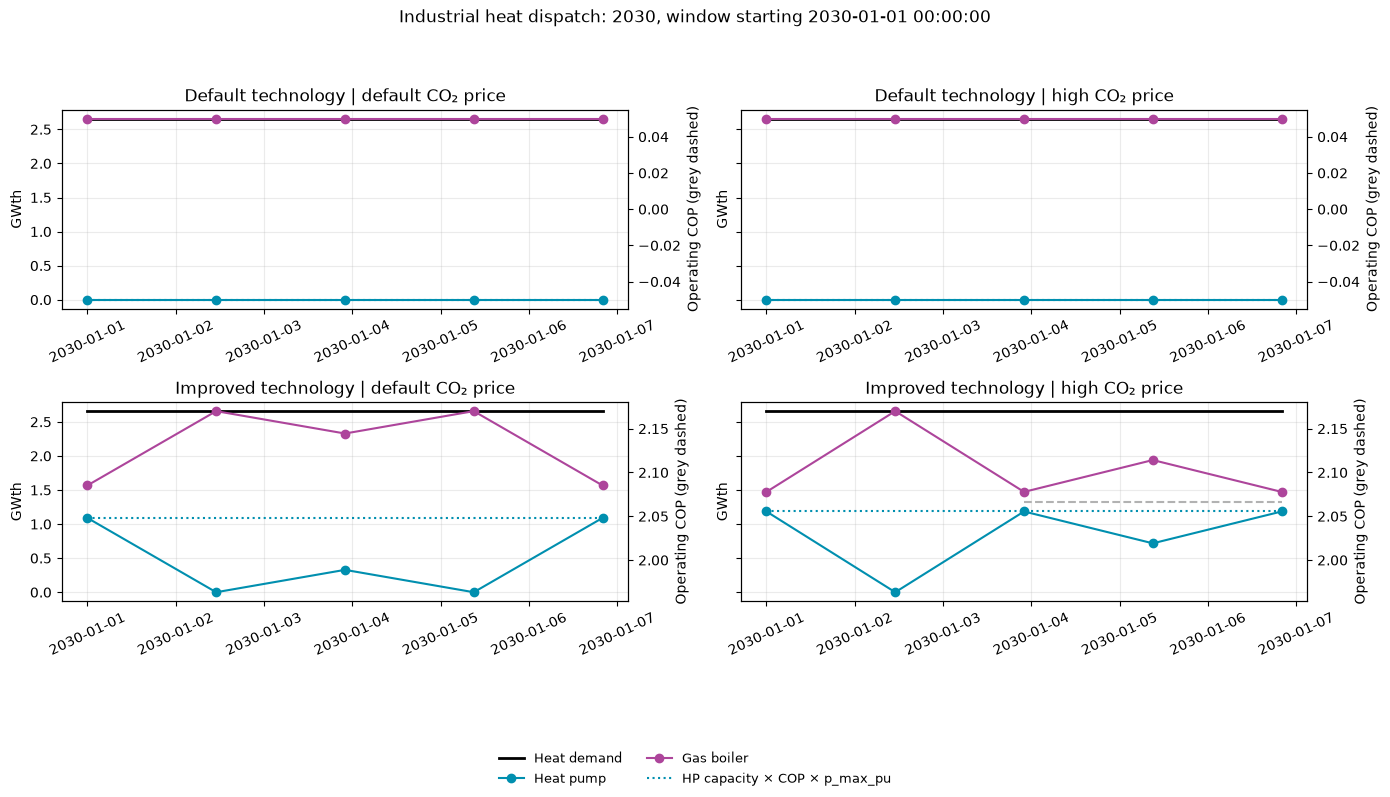

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

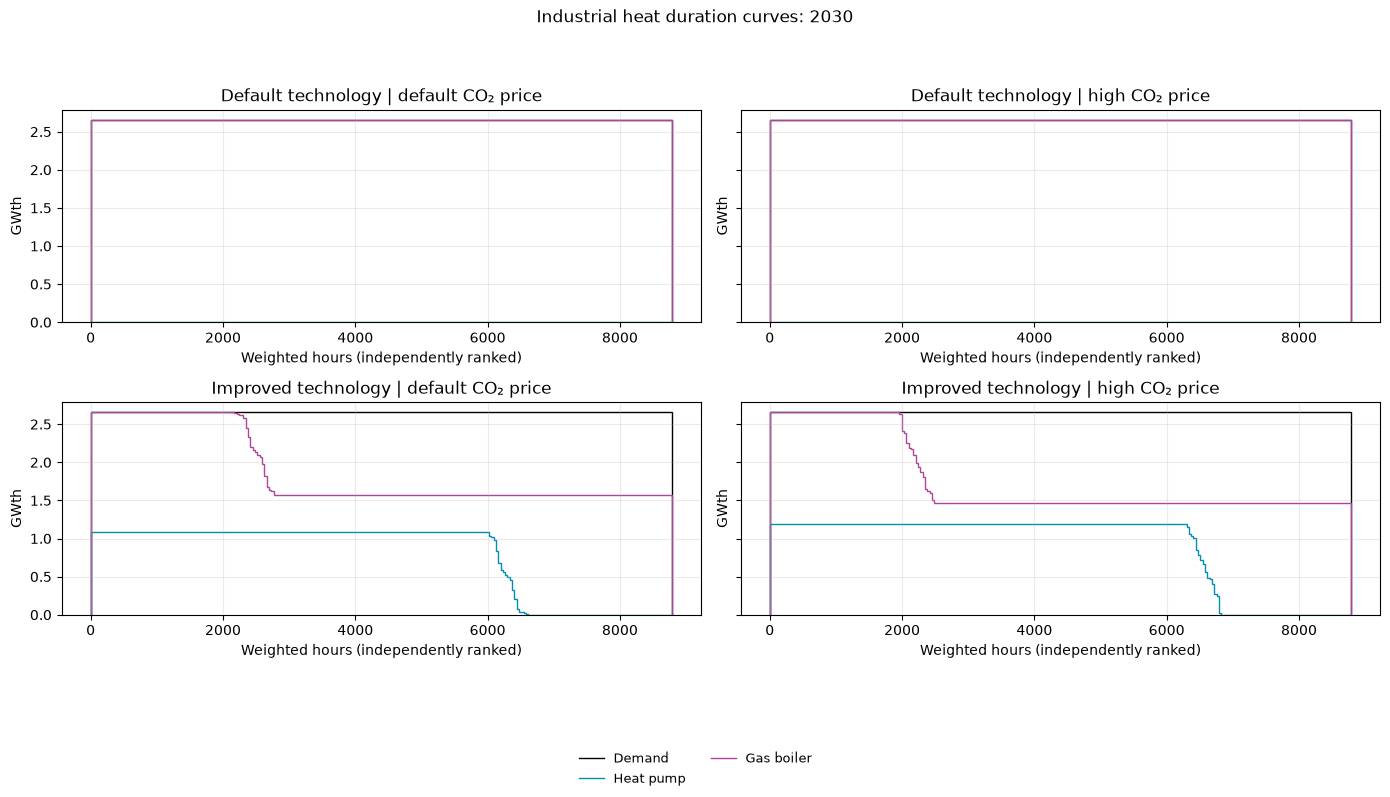

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

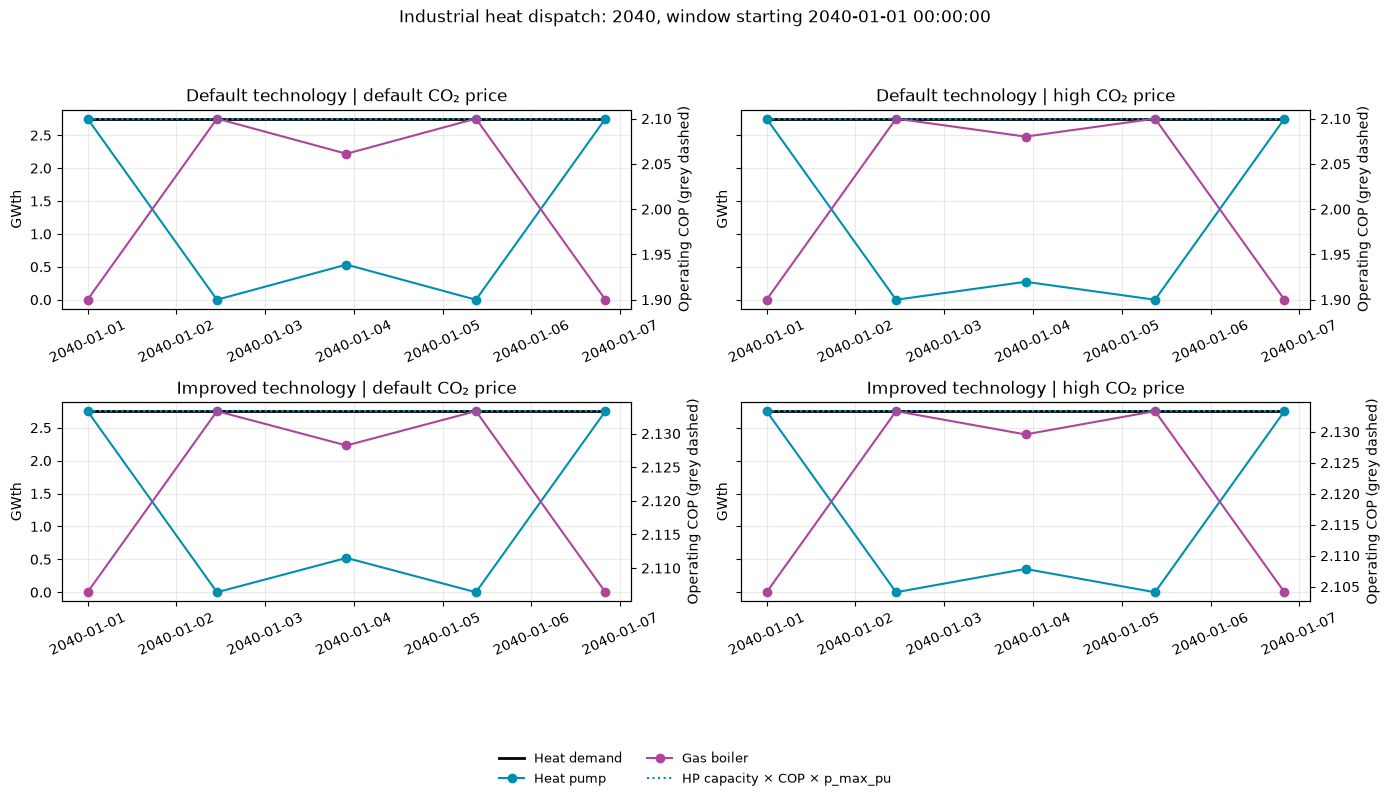

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

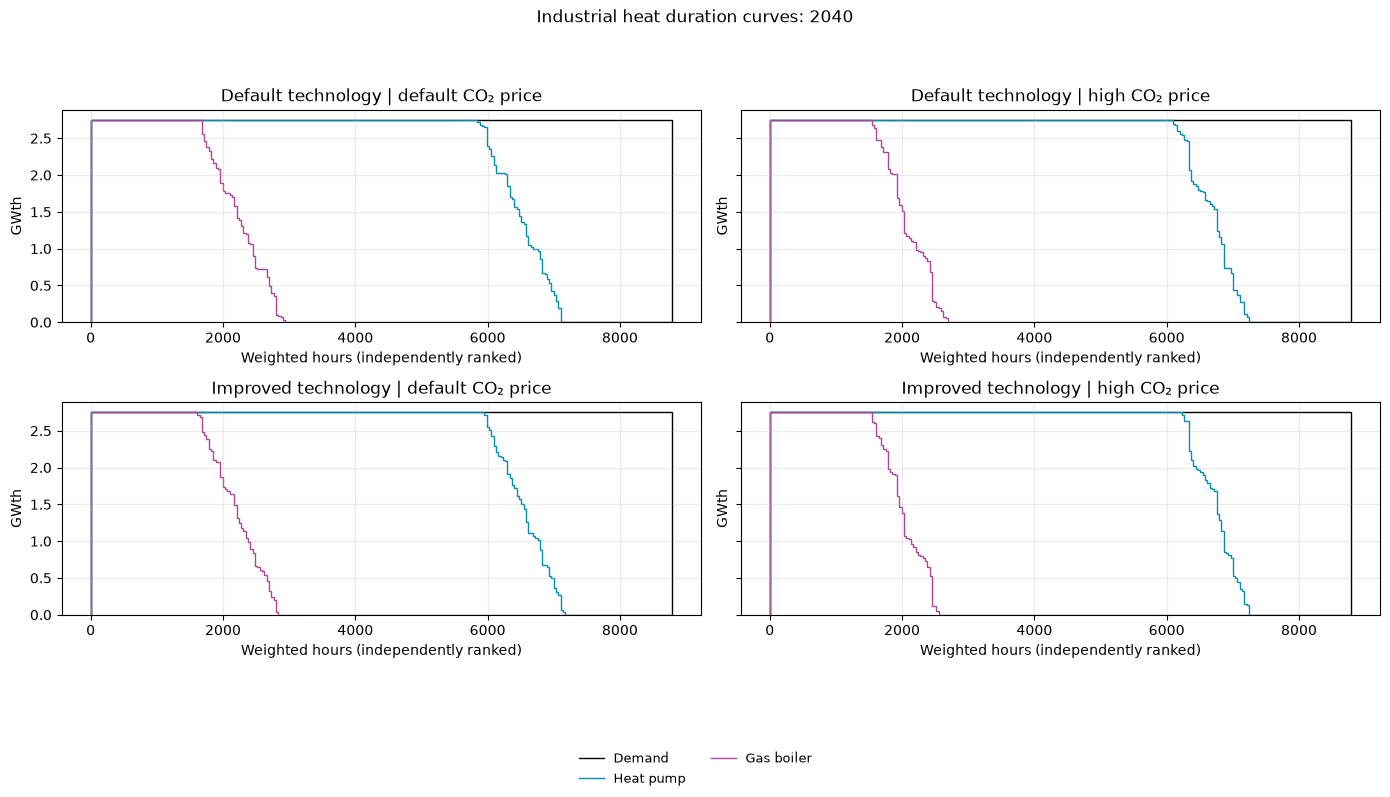

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

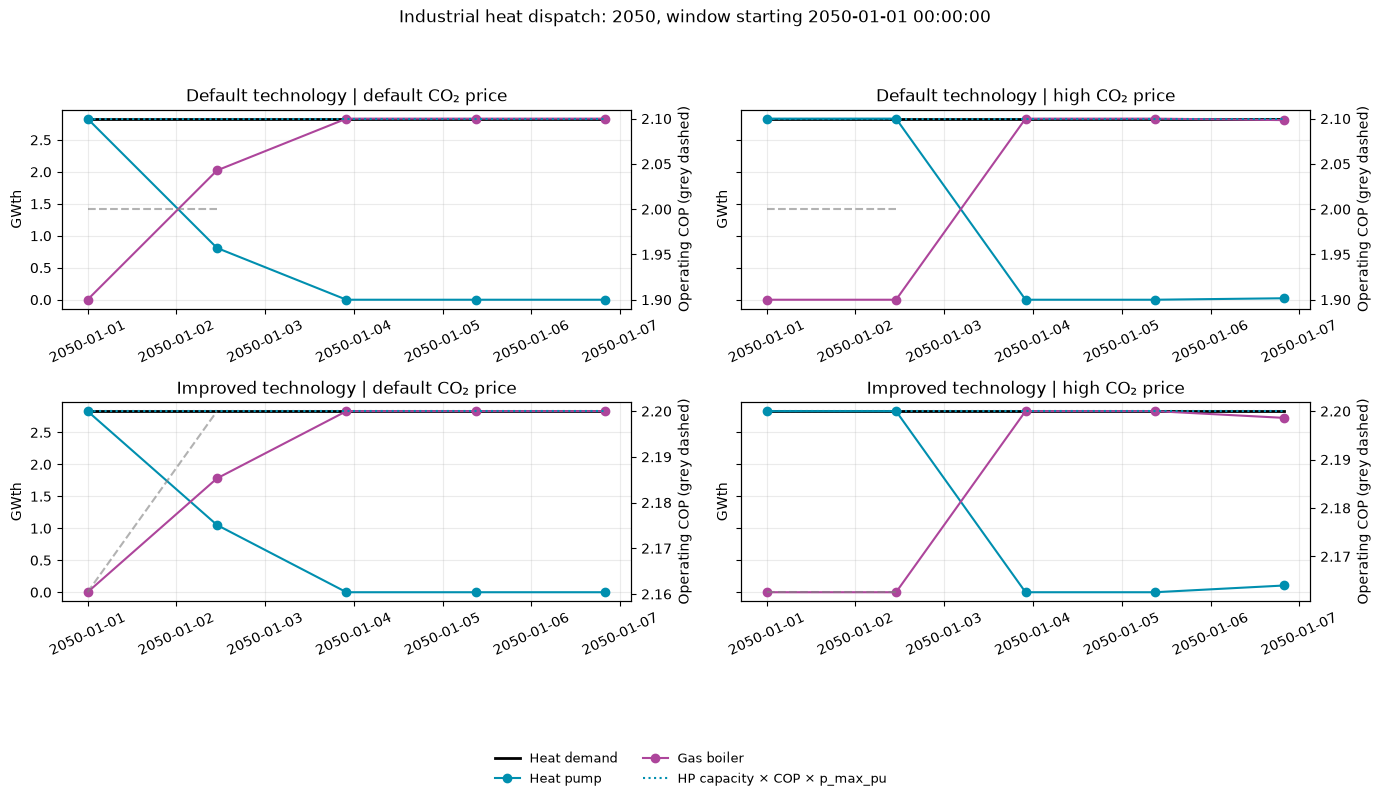

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/2709460072.py:29: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  return ids[n.get_active_assets('Link', year).reindex(ids).fillna(False).to_numpy()]
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_97353/27

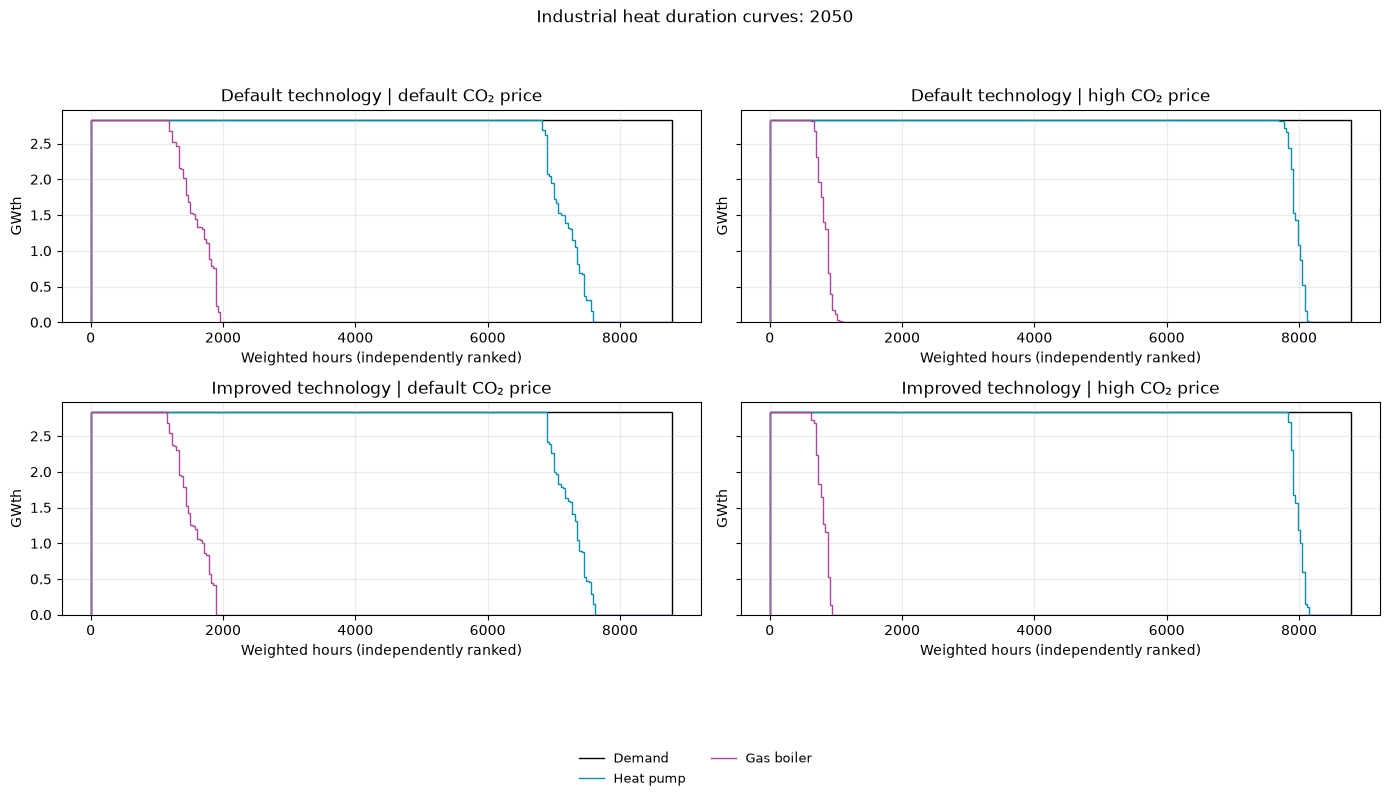

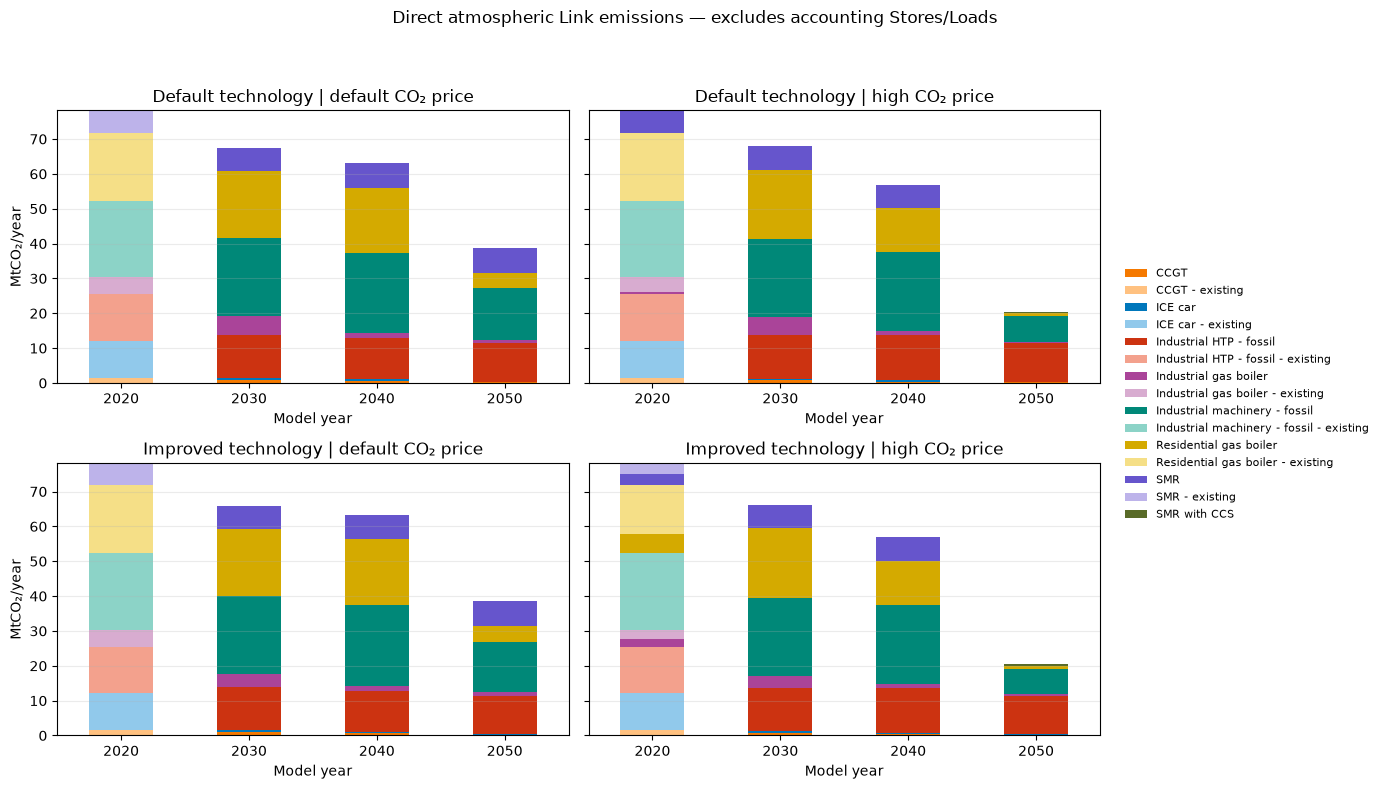


SIGNED NET ATMOSPHERIC LINK INJECTIONS (MtCO2/year)
      default_tech_low_carbon  default_tech_high_carbon  improved_tech_low_carbon  improved_tech_high_carbon
2020                  78.2297                   78.2297                   78.2297                    78.2297
2030                  67.4757                   68.0255                   65.9371                    66.2549
2040                  63.1100                   56.9295                   63.3167                    56.8760
2050                  38.8143                   20.5025                   38.5187                    20.4301
These are Link emissions, not necessarily the complete model emissions inventory.

NON-LINK COMPONENTS ON ATMOSPHERIC CO2 BUSES

stores
                           bus         carrier
name                                          
CO2 atmosphere  CO2 atmosphere  CO2 atmosphere


ValueError: Missing solved storage_units p dispatch.

In [72]:
# Uses your previously loaded networks, SCENARIOS, LABELS and COLORS.
# All figures are displayed separately in a Jupyter notebook.

YEARS_TO_INSPECT = [2020, 2030, 2040, 2050]
WINDOW_HOURS = 168  # At 35-hour resolution this is roughly five snapshots.
# Use 336 or 672 for a clearer view over two or four nominal weeks.

# Optional: set the EXACT useful-service bus carrier after inspecting the
# printed candidate list. Leave None to avoid guessing its name or units.
MACHINERY_SERVICE_CARRIER = None

palette = globals().get('tech_colors', {})

# 1. Actual loaded inputs, including detailed values for each vintage.
parameter_table = plot_loaded_hp_parameters(networks, SCENARIOS, LABELS, COLORS)
print('\nLOADED HEAT-PUMP PARAMETERS')
print(parameter_table.to_string(index=False))

# Ratios for matching assets: improved versus default, separately by carbon case.
# Asset names must match; unmatched names remain visible in parameter_table.
for default, improved in [
    ('default_tech_low_carbon', 'improved_tech_low_carbon'),
    ('default_tech_high_carbon', 'improved_tech_high_carbon'),
]:
    a = parameter_table[parameter_table.scenario.eq(default)].set_index('Link')
    b = parameter_table[parameter_table.scenario.eq(improved)].set_index('Link')
    common = a.index.intersection(b.index)
    if len(common):
        ratios = pd.DataFrame({
            'build_year': b.loc[common, 'build_year'],
            'capital_cost_ratio': b.loc[common, 'capital_cost'].div(a.loc[common, 'capital_cost'].replace(0, np.nan)),
            'static_COP_ratio': b.loc[common, 'efficiency'].div(a.loc[common, 'efficiency'].replace(0, np.nan)),
        })
        print(f'\nIMPROVED / DEFAULT PARAMETER RATIOS: {improved}')
        print(ratios.to_string())
    else:
        print(f'\nNo matching asset names for parameter ratios: {default} / {improved}.')

# 2. Capacity, COP, full-load hours, and availability-adjusted utilisation.
hp_tables = plot_hp_diagnostics(networks, SCENARIOS, LABELS, COLORS)
hp_summary = pd.concat(hp_tables, names=['scenario', 'year'])
print('\nANNUAL HEAT-PUMP DIAGNOSTICS')
print(hp_summary.round(4).to_string())

capacity_limits = hp_capacity_limits(networks, SCENARIOS)
print('\nACTIVE HEAT-PUMP CAPACITY BOUNDS')
print(capacity_limits.to_string(index=False))
print('\nGLOBAL CONSTRAINTS (if any; inspect separately from asset bounds)')
for scenario in SCENARIOS:
    gc = networks[scenario].global_constraints
    if not gc.empty:
        print(f'\n{LABELS[scenario]}\n{gc.to_string()}')

# 3. Coincident heat dispatch and independently ranked duration curves.
for year in YEARS_TO_INSPECT:
    plot_heat_dispatch(networks, SCENARIOS, LABELS, year=year,
                       start=None, window_hours=WINDOW_HOURS)
    plot_heat_duration(networks, SCENARIOS, LABELS, year=year)

# 4. Direct atmospheric Link flows, without the black accounting withdrawal.
emissions_tables = plot_link_emissions(networks, SCENARIOS, LABELS, palette)
print('\nSIGNED NET ATMOSPHERIC LINK INJECTIONS (MtCO2/year)')
print(pd.DataFrame({s: d.sum(axis=1) for s, d in emissions_tables.items()}).round(4).to_string())
print('These are Link emissions, not necessarily the complete model emissions inventory.')

# Show components attached to atmospheric buses, so bookkeeping and any
# non-Link physical emissions/removals can be inspected explicitly.
reference = networks[SCENARIOS[0]]
atmospheric_buses = reference.buses.index[reference.buses.carrier.eq(CO2_CARRIER)]
print('\nNON-LINK COMPONENTS ON ATMOSPHERIC CO2 BUSES')
for component in ['stores', 'loads', 'generators', 'storage_units']:
    assets = getattr(reference, component)
    if not assets.empty:
        attached = assets[assets.bus.isin(atmospheric_buses)]
        if not attached.empty:
            cols = [c for c in ['bus', 'carrier'] if c in attached]
            print(f'\n{component}\n{attached[cols].to_string()}')

# 5. Snapshot hours and numerical bus accounting; cross-check statistics.
audit_table, statistics_check = audit_networks(networks, SCENARIOS)
print('\nSNAPSHOT WEIGHTS AND BUS-RESIDUAL AUDIT')
print(audit_table.to_string(float_format=lambda v: f'{v:.6g}'))
print('\nMANUAL VS STATISTICS HEAT-PUMP ANNUAL ENERGY')
print(statistics_check.to_string(float_format=lambda v: f'{v:.8g}'))
print('\nHours should match your intended represented year (often 8760).')
print('Annual totals here deliberately exclude decade/investment-period weights.')
print('Residuals should be small relative to system flows; CO2 uses different physical units.')

# 6. Discover machinery service buses without inventing their exact names.
all_carriers = sorted(set().union(*(set(n.buses.carrier.dropna()) for n in networks.values())))
candidates = [c for c in all_carriers if 'machin' in str(c).lower()]
print('\nPOSSIBLE MACHINERY BUS CARRIERS:', candidates)
print('\nALL BUS CARRIERS:', all_carriers)

if MACHINERY_SERVICE_CARRIER is not None:
    machinery_tables = plot_service_balance(
        networks, SCENARIOS, LABELS, MACHINERY_SERVICE_CARRIER, palette
    )
    print('\nMACHINERY SERVICE WITHDRAWALS BY CARRIER')
    for scenario, d in machinery_tables.items():
        print(f'\n{LABELS[scenario]}')
        print(d.clip(upper=0).round(5).to_string())
    print('Compare demand withdrawals across scenarios; do not equate fuel-input MWh with useful service.')
else:
    print('To plot machinery useful service, set MACHINERY_SERVICE_CARRIER to its exact bus carrier and rerun this cell.')